# VisionQC – Controle de qualidade visual de peças de fundição

**Caso prático:** VisionQC – controle de qualidade visual de peças metálicas (classificação binária: `correcta` / `defectuosa`).

Preparação do dataset (Kaggle → estrutura visionqc/)
1. Tarefa 1 – Carregamento e revisão do dataset
2. Tarefa 2 – Visualização de exemplos
3. Tarefa 3 – Pré-processamento e augmentação
4. Tarefa 4 – Modelo com transfer learning (MobileNetV2 congelada)
5. Tarefa 5 – Treinamento
6. Tarefa 6 – Avaliação
7. Tarefa 7 – Análise de erros
8. Tarefa 8 – Fine-tuning da MobileNetV2
9. Tarefa 9 – Grad-CAM: onde o modelo olha

## 0. Configuração inicial

In [ ]:
# IMPORTAÇÕES E SEMENTES

import os
import random
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## 1. Preparação do dataset

Origem: dataset público do Kaggle (Casting Product Image Data for Quality Inspection).

Classes originais: ok_front (peças sem defeitos) e def_front (peças defeituosas).

Amostra utilizada: dataset completo, com as 7.348 imagens disponíveis (3.137 corretas e 4.211 defeituosas), sem subamostragem.

Nomes de classe adaptados: correcta e defectuosa.

Divisão do conjunto (70% / 15% / 15%), feita separadamente em cada classe:

* Treinamento (Train, 70%): 5.142 imagens (2.195 correcta e 2.947 defectuosa).

* Validação (Val, 15%): 1.101 imagens (470 correcta e 631 defectuosa).

* Teste (Test, 15%): 1.105 imagens (472 correcta e 633 defectuosa).


In [ ]:
# BAIXAR O DATASET ORIGINAL DO KAGGLE

!pip install -q kagglehub

import kagglehub

ruta_kaggle = kagglehub.dataset_download(
    "ravirajsinh45/real-life-industrial-dataset-of-casting-product"
)

print("Dataset baixado em:", ruta_kaggle)

Using Colab cache for faster access to the 'real-life-industrial-dataset-of-casting-product' dataset.
Dataset baixado em: /kaggle/input/real-life-industrial-dataset-of-casting-product


In [ ]:
# ok_front  -> correcta
# def_front -> defectuosa

ORIGEN = Path(ruta_kaggle)
EXTENSIONES = {".jpg", ".jpeg", ".png"}


def listar_imagenes(nombre_carpeta):

    carpetas = [
        c for c in ORIGEN.rglob(nombre_carpeta)
        if c.is_dir()
    ]

    # O dataset traz também uma versão 512x512:
    # ficamos só com "casting_data" para não duplicar
    preferidas = [
        c for c in carpetas
        if "casting_data" in c.parts
    ]

    if preferidas:
        carpetas = preferidas

    imagenes = []

    for carpeta in carpetas:
        imagenes += [
            p for p in carpeta.iterdir()
            if p.suffix.lower() in EXTENSIONES
        ]

    return sorted(imagenes)


originales = {
    "correcta": listar_imagenes("ok_front"),
    "defectuosa": listar_imagenes("def_front")
}

for clase, archivos in originales.items():
    print(clase, "→", len(archivos), "imagens disponíveis")

correcta → 3137 imagens disponíveis
defectuosa → 4211 imagens disponíveis


In [ ]:
# CRIAR A ESTRUTURA visionqc/
# Usa TODAS as imagens do dataset e reparte cada classe em train (70%) / val (15%) / test (15%)

DESTINO = Path("visionqc")

if DESTINO.exists():
    shutil.rmtree(DESTINO)

for clase, archivos in originales.items():

    # Embaralha todas as imagens da classe (com a semente fixada)
    muestra = random.sample(archivos, len(archivos))

    n_train = int(len(muestra) * 0.70)
    n_val = int(len(muestra) * 0.15)

    partes = {
        "train": muestra[:n_train],
        "val": muestra[n_train:n_train + n_val],
        "test": muestra[n_train + n_val:]
    }

    for split, lista in partes.items():

        carpeta = DESTINO / split / clase
        carpeta.mkdir(parents=True, exist_ok=True)

        for archivo in lista:

            # Prefixo com a pasta de origem para evitar nomes repetidos
            nuevo_nombre = f"{archivo.parent.parent.name}_{archivo.name}"

            shutil.copy(archivo, carpeta / nuevo_nombre)

print("Estrutura visionqc/ criada com sucesso")

Estrutura visionqc/ criada com sucesso


## Tarefa 1 – Carregamento e revisão do dataset

Contamos o número de imagens por classe e por partição e verificamos como está o equilíbrio da divisão.

In [ ]:
# NÚMERO DE IMAGENS POR CLASSE E PARTIÇÃO

import tensorflow as tf
import os

for split in ['train', 'val', 'test']:
    for cls in ['correcta', 'defectuosa']:
        path = f'visionqc/{split}/{cls}'
        n = len(os.listdir(path))
        print(f'{split}/{cls}: {n} imagens')

train/correcta: 2195 imagens
train/defectuosa: 2947 imagens
val/correcta: 470 imagens
val/defectuosa: 631 imagens
test/correcta: 472 imagens
test/defectuosa: 633 imagens


In [ ]:
# RESUMO DO EQUILÍBRIO ENTRE CLASSES

total = 0

for split in ['train', 'val', 'test']:

    n_ok = len(os.listdir(f'visionqc/{split}/correcta'))
    n_def = len(os.listdir(f'visionqc/{split}/defectuosa'))

    total += n_ok + n_def

    print(
        f"{split:5} → total {n_ok + n_def:3} | "
        f"correcta {n_ok / (n_ok + n_def):.0%} | "
        f"defectuosa {n_def / (n_ok + n_def):.0%}"
    )

print("\nTotal de imagens do dataset:", total)

train → total 5142 | correcta 43% | defectuosa 57%
val   → total 1101 | correcta 43% | defectuosa 57%
test  → total 1105 | correcta 43% | defectuosa 57%

Total de imagens do dataset: 7348


In [ ]:
# VERIFICAR TAMANHO, CANAIS E IMAGENS CORROMPIDAS

from PIL import Image

DATASET = Path("visionqc")

errores = []
tamanos = set()

for split in ["train", "val", "test"]:
    for clase in ["correcta", "defectuosa"]:
        for archivo in (DATASET / split / clase).iterdir():

            try:
                with Image.open(archivo) as img:
                    img.verify()

                with Image.open(archivo) as img:
                    tamanos.add((img.size, img.mode))

            except Exception as e:
                errores.append((archivo, str(e)))

print("Tamanhos e modos de cor encontrados:", tamanos)

if len(errores) == 0:
    print("✓ Nenhuma imagem corrompida encontrada")
else:
    print("⚠ Imagens com problemas:")
    for archivo, error in errores:
        print(archivo, "→", error)

Tamanhos e modos de cor encontrados: {((300, 300), 'RGB')}
✓ Nenhuma imagem corrompida encontrada


Conjunto com leve desequilíbrio entre as classes, igual em todas as partições: cerca de 43 % correcta e 57 % defectuosa. É a proporção do dataset original, mantida porque a divisão é feita por classe. Não é um desequilíbrio severo, por isso não se aplicam técnicas de compensação (como class weights ou oversampling), mas ele obriga a olhar precision e recall por classe e não só a accuracy: um modelo que respondesse sempre «defectuosa» já acertaria cerca de 57 %.

Integridade dos dados: a verificação acima lista qualquer imagem que não abra. Se aparecer a mensagem «✓ Nenhuma imagem corrompida encontrada», todas as imagens abrem sem falhas.

Resolução nativa: a verificação imprime os tamanhos e modos de cor encontrados. Neste dataset de fundição o esperado é $300 \times 300$ pixels em formato RGB (3 canais).

Pré-processamento: ajuste automático para $224 \times 224$ por meio do flow_from_directory, para compatibilidade direta com a entrada padrão da MobileNetV2.

## Tarefa 2 – Visualização de exemplos

Grade de 8 imagens do conjunto de treinamento: 4 de cada classe.

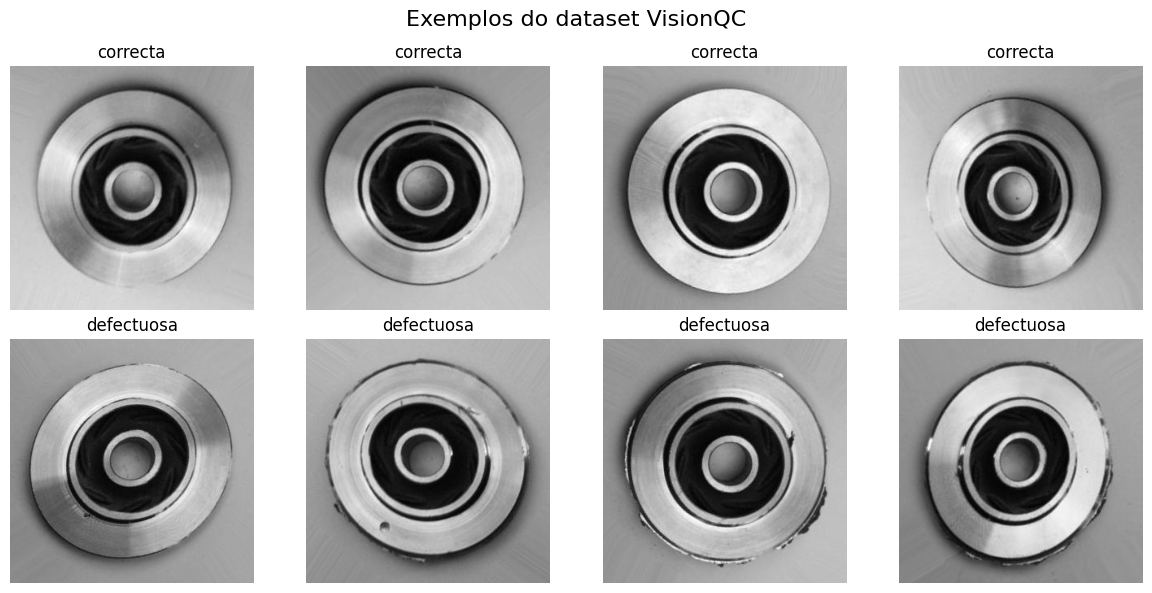

In [ ]:
# MOSTRAR 8 IMAGENS DO DATASET
# 4 peças corretas e 4 defeituosas

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, cls in enumerate(['correcta', 'defectuosa']):
    imgs = sorted(os.listdir(f'visionqc/train/{cls}'))[:4]
    for j, img_name in enumerate(imgs):
        img = plt.imread(f'visionqc/train/{cls}/{img_name}')
        axes[i, j].imshow(img, cmap='gray')
        axes[i, j].set_title(cls)
        axes[i, j].axis('off')

plt.suptitle("Exemplos do dataset VisionQC", fontsize=16)
plt.tight_layout()
plt.show()

**Comentário Tarefa 2:** as peças corretas mostram uma coroa externa limpa, de borda regular e superfície uniforme. As defeituosas apresentam irregularidades como borda externa rugosa ou com rebarbas, pequenas marcas escuras ou poros na superfície e zonas com acabamento desigual. Alguns defeitos são muito sutis e se distinguem com dificuldade de uma peça correta, o que antecipa que é aí que estará a maior dificuldade do modelo. A iluminação e a posição da peça também variam, o que justifica a augmentação.

## Tarefa 3 – Pré-processamento e augmentação

- **Train:** reescala (`1/255`) + augmentação básica (giro horizontal, rotação de ±10°, zoom de 10 %).
- **Val e test:** **somente** reescala, para avaliar sobre imagens sem modificação.
- O test é lido com `shuffle=False` para que as previsões coincidam com `test_data.classes`.

In [ ]:
# GERADORES DE IMAGENS
# Augmentação SOMENTE no treinamento

from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224)
BATCH = 16

train_gen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    rotation_range=10,
    zoom_range=0.1
)

val_test_gen = ImageDataGenerator(rescale=1./255)

train_data = train_gen.flow_from_directory(
    'visionqc/train', target_size=IMG_SIZE, batch_size=BATCH, class_mode='binary')

val_data = val_test_gen.flow_from_directory(
    'visionqc/val', target_size=IMG_SIZE, batch_size=BATCH, class_mode='binary')

test_data = val_test_gen.flow_from_directory(
    'visionqc/test', target_size=IMG_SIZE, batch_size=BATCH, class_mode='binary',
    shuffle=False)

print("\nÍndices de classe:", train_data.class_indices)

Found 5142 images belonging to 2 classes.
Found 1101 images belonging to 2 classes.
Found 1105 images belonging to 2 classes.

Índices de classe: {'correcta': 0, 'defectuosa': 1}


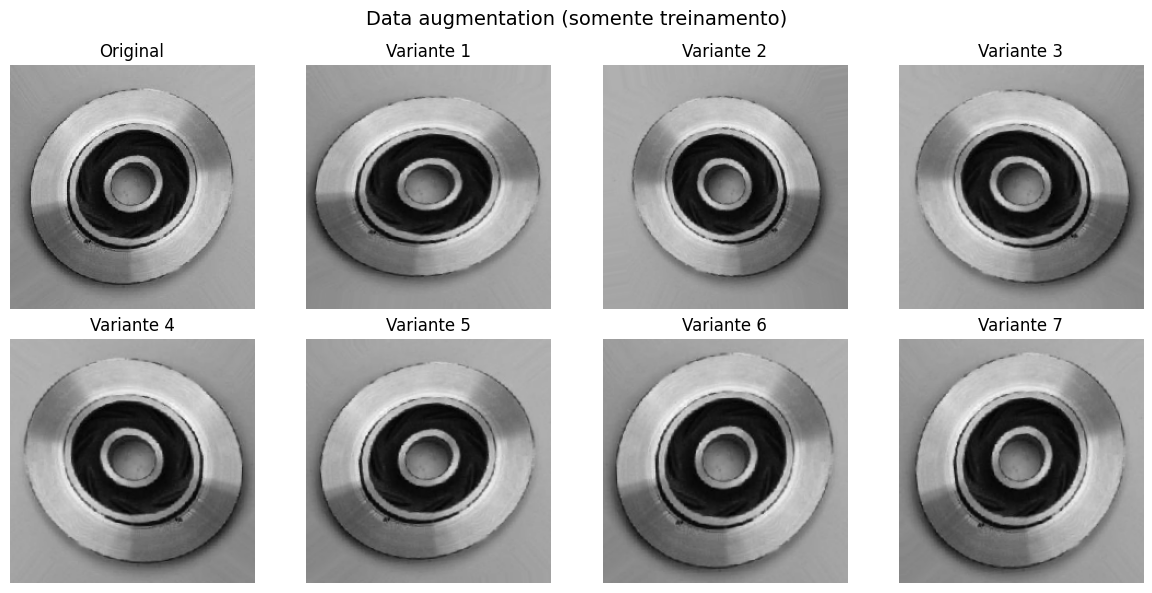

In [ ]:
# Mostra várias versões modificadas de uma
# mesma imagem de treinamento

from tensorflow.keras.preprocessing.image import load_img, img_to_array

ruta_ejemplo = sorted(Path("visionqc/train/defectuosa").glob("*"))[0]

x = img_to_array(load_img(ruta_ejemplo, target_size=IMG_SIZE))

plt.figure(figsize=(12, 6))

for i in range(8):

    variante = train_gen.random_transform(x)

    plt.subplot(2, 4, i + 1)
    plt.imshow(variante.astype("uint8"))
    plt.title("Original" if i == 0 else f"Variante {i}")
    plt.axis("off")

    if i == 0:
        plt.imshow(x.astype("uint8"))

plt.suptitle("Data augmentation (somente treinamento)", fontsize=14)
plt.tight_layout()
plt.show()

**Comentário Tarefa 3:** a augmentação gera pequenas variações (espelho, rotação, zoom) que tornam o modelo mais robusto às mudanças de posição e orientação da peça e ajudam a reduzir o sobreajuste, sem alterar a natureza do defeito. Validação e teste não são aumentados, para que as métricas reflitam o desempenho sobre imagens reais sem modificação.

## Tarefa 4 – Modelo com transfer learning

Carregamos a **MobileNetV2** com pesos do ImageNet, **congelamos toda a base** e adicionamos uma cabeça de classificação: `GlobalAveragePooling2D` → `Dense(64, relu)` → `Dropout(0.3)` → `Dense(1, sigmoid)`.

> **Nota técnica:** os geradores entregam pixels em [0, 1], mas a MobileNetV2 foi pré-treinada com entradas em [-1, 1]. Adicionamos uma camada `Rescaling` na entrada do modelo para converter o intervalo, e a base é chamada com `training=False` para que as camadas de BatchNormalization permaneçam congeladas.

In [ ]:
# MOBILENETV2 PRÉ-TREINADA + CABEÇA DE CLASSIFICAÇÃO

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, Model

base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False,
                         weights='imagenet')

# Congelamos TODA a base (antes de compilar)
base_model.trainable = False

# Entrada [0,1] -> [-1,1], que é o intervalo esperado pela MobileNetV2
inputs = tf.keras.Input(shape=(224, 224, 3))
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)

# A base é executada sempre em modo de inferência
x = base_model(x, training=False)

# Cabeça de classificação
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.3)(x)
output = layers.Dense(1, activation='sigmoid')(x)

model = Model(inputs=inputs, outputs=output)

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,033 (8.93 MB)

 Trainable params: 82,049 (320.50 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# VERIFICAR QUE A BASE ESTÁ CONGELADA
# Só devem ser treinadas as 4 matrizes da cabeça (2 camadas Dense: pesos + vieses)

print("Base treinável?:", base_model.trainable)
print("Variáveis treináveis do modelo:", len(model.trainable_weights))

n_entrenables = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
n_congelados = sum(int(np.prod(w.shape)) for w in model.non_trainable_weights)

print(f"Parâmetros treináveis  : {n_entrenables:,}")
print(f"Parâmetros congelados  : {n_congelados:,}")

assert base_model.trainable is False
assert len(model.trainable_weights) == 4
print("\n✓ Base congelada corretamente")

Base treinável?: False
Variáveis treináveis do modelo: 4
Parâmetros treináveis  : 82,049
Parâmetros congelados  : 2,257,984

✓ Base congelada corretamente


## Tarefa 5 – Treinamento

Treinamento por no máximo 10 épocas com `EarlyStopping` (paciência 3, recuperando os melhores pesos segundo `val_loss`).

In [ ]:
# TREINAR A CABEÇA DE CLASSIFICAÇÃO

from tensorflow.keras.callbacks import EarlyStopping

callback = EarlyStopping(patience=3, restore_best_weights=True)

history = model.fit(train_data, validation_data=val_data, epochs=10,
                    callbacks=[callback])

Epoch 1/10
322/322 ━━━━━━━━━━━━━━━━━━━━ 115s 319ms/step - accuracy: 0.9121 - loss: 0.2154 - val_accuracy: 0.9827 - val_loss: 0.0730
Epoch 2/10
322/322 ━━━━━━━━━━━━━━━━━━━━ 84s 262ms/step - accuracy: 0.9780 - loss: 0.0725 - val_accuracy: 0.9900 - val_loss: 0.0479
Epoch 3/10
322/322 ━━━━━━━━━━━━━━━━━━━━ 85s 265ms/step - accuracy: 0.9837 - loss: 0.0547 - val_accuracy: 0.9909 - val_loss: 0.0291
Epoch 4/10
322/322 ━━━━━━━━━━━━━━━━━━━━ 92s 284ms/step - accuracy: 0.9817 - loss: 0.0543 - val_accuracy: 0.9827 - val_loss: 0.0598
Epoch 5/10
322/322 ━━━━━━━━━━━━━━━━━━━━ 74s 229ms/step - accuracy: 0.9858 - loss: 0.0453 - val_accuracy: 0.9918 - val_loss: 0.0262
Epoch 6/10
322/322 ━━━━━━━━━━━━━━━━━━━━ 78s 244ms/step - accuracy: 0.9874 - loss: 0.0386 - val_accuracy: 0.9909 - val_loss: 0.0236
Epoch 7/10
322/322 ━━━━━━━━━━━━━━━━━━━━ 74s 229ms/step - accuracy: 0.9903 - loss: 0.0341 - val_accuracy: 0.9955 - val_loss: 0.0185
Epoch 8/10
322/322 ━━━━━━━━━━━━━━━━━━━━ 69s 215ms/step - accuracy: 0.9912 - loss: 

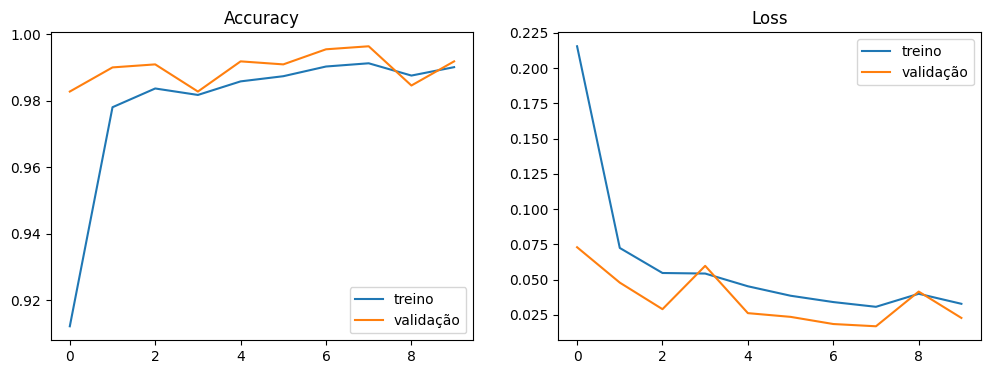

In [ ]:
# CURVAS DE ACCURACY E LOSS

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='treino')
plt.plot(history.history['val_accuracy'], label='validação')
plt.title('Accuracy'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='treino')
plt.plot(history.history['val_loss'], label='validação')
plt.title('Loss'); plt.legend()

plt.show()

**Comentário Tarefa 5:** o treinamento completou as 10 épocas e o `EarlyStopping` (paciência 3) não chegou a ser acionado, porque a `val_loss` não ficou três épocas seguidas sem melhorar: caiu de 0,0730 (época 1) até um mínimo de 0,0169 (época 8), subiu para 0,0415 na época 9 e voltou a 0,0228 na época 10. A accuracy de treinamento sobe de 0,912 para 0,990 e a de validação vai de 0,983 para 0,992, com máximo de 0,996 na época 8. Não há sinais de sobreajuste: treino e validação terminam praticamente iguais. A validação fica acima do treino no início porque, no treino, atuam a augmentação e o Dropout. As oscilações da validação (épocas 4 e 9) são pequenas e se recuperam na época seguinte. As curvas já estão perto de estabilizar, então treinar mais épocas traria pouco ganho.

## Tarefa 6 – Avaliação sobre o conjunto de teste

Tomamos `defectuosa` como classe positiva. Em controle de qualidade, o **recall de `defectuosa`** é a métrica crítica: um falso negativo é uma peça defeituosa que é dada como boa e chega ao cliente.

70/70 ━━━━━━━━━━━━━━━━━━━━ 11s 118ms/step
              precision    recall  f1-score   support

    correcta       0.99      1.00      0.99       472
  defectuosa       1.00      0.99      1.00       633

    accuracy                           1.00      1105
   macro avg       0.99      1.00      1.00      1105
weighted avg       1.00      1.00      1.00      1105



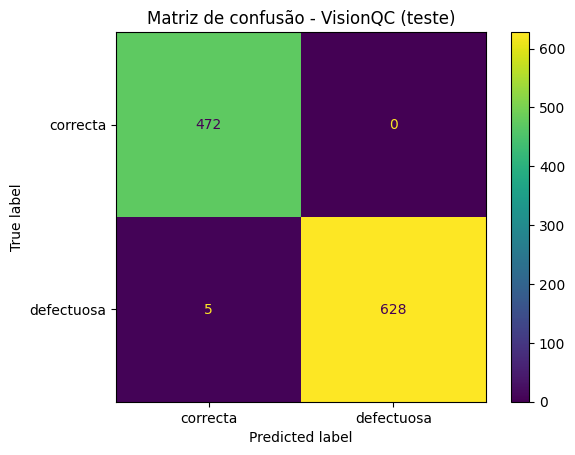

In [ ]:
# PREVISÕES SOBRE O TESTE + RELATÓRIO DE CLASSIFICAÇÃO

from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import numpy as np

y_pred_prob = model.predict(test_data)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()
y_true = test_data.classes

print(classification_report(y_true, y_pred, target_names=['correcta', 'defectuosa']))

ConfusionMatrixDisplay.from_predictions(y_true, y_pred,
                                        display_labels=['correcta', 'defectuosa'])
plt.title("Matriz de confusão - VisionQC (teste)")
plt.show()

In [ ]:
# MÉTRICAS PRINCIPAIS E VALORES DA MATRIZ

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, zero_division=0)
rec = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

print(f"Accuracy  : {acc:.3f}")
print(f"Precision : {prec:.3f}  (das peças marcadas como defectuosa, quantas realmente são)")
print(f"Recall    : {rec:.3f}  (das peças defectuosa, quantas são detectadas)")
print(f"F1-score  : {f1:.3f}")

tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

print("\nVerdadeiros negativos (correcta → correcta)     :", tn)
print("Falsos positivos      (correcta → defectuosa)   :", fp)
print("Falsos negativos      (defectuosa → correcta)   :", fn)
print("Verdadeiros positivos (defectuosa → defectuosa) :", tp)

Accuracy  : 0.995
Precision : 1.000  (das peças marcadas como defectuosa, quantas realmente são)
Recall    : 0.992  (das peças defectuosa, quantas são detectadas)
F1-score  : 0.996

Verdadeiros negativos (correcta → correcta)     : 472
Falsos positivos      (correcta → defectuosa)   : 0
Falsos negativos      (defectuosa → correcta)   : 5
Verdadeiros positivos (defectuosa → defectuosa) : 628


## Tarefa 7 – Análise de erros

Mostramos quatro imagens classificadas incorretamente (as de maior confiança errada) com seu rótulo real e a previsão do modelo. Se o modelo cometer menos de quatro erros, completamos com os acertos mais próximos do limiar, marcados como «duvidoso».

Total de erros no teste: 5 de 1105


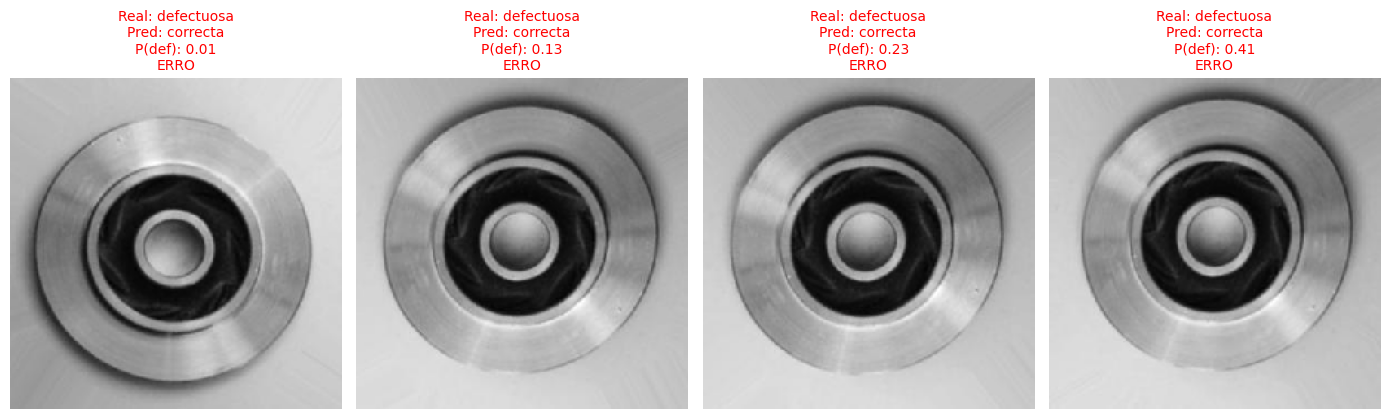

In [ ]:
# IDENTIFICAR E MOSTRAR 4 ERROS DE CLASSIFICAÇÃO

from tensorflow.keras.preprocessing.image import load_img

nombres = ['correcta', 'defectuosa']
rutas, probs = np.array(test_data.filepaths), y_pred_prob.flatten()

# Erros, ordenados pela confiança do erro (mais longe de 0.5 primeiro)
idx_error = [i for i in np.argsort(-np.abs(probs - 0.5)) if y_pred[i] != y_true[i]]
print(f"Total de erros no teste: {len(idx_error)} de {len(y_true)}")

# Completar com os acertos mais duvidosos se houver menos de 4
dudosos = [i for i in np.argsort(np.abs(probs - 0.5)) if i not in idx_error]
elegidos = (idx_error + dudosos)[:4]

# Visualização
plt.figure(figsize=(14, 4))
for k, i in enumerate(elegidos):
    es_error = y_pred[i] != y_true[i]
    plt.subplot(1, 4, k + 1)
    plt.imshow(load_img(rutas[i], target_size=IMG_SIZE))
    plt.title(
        f"Real: {nombres[y_true[i]]}\nPred: {nombres[y_pred[i]]}\n"
        f"P(def): {probs[i]:.2f}\n{'ERRO' if es_error else 'duvidoso'}",
        fontsize=10, color="red" if es_error else "darkorange"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

**Análise de padrões:** o modelo comete 5 erros em 1.105 imagens de teste (0,5 %), todos falsos negativos (defectuosa → correcta), e nenhum falso positivo. A matriz de confusão da Tarefa 6 mostra as 472 peças corretas bem classificadas e 628 das 633 defeituosas detectadas. A célula acima mostra os 4 erros de maior confiança errada (o quinto erro não aparece), com P(defectuosa) de 0,01, 0,13, 0,23 e 0,41:

- **Todos os erros são defeitos que passam como peças boas:** a dificuldade do modelo está em detectar defeitos, e não em confundir peças boas com defeituosas.
- **Defeitos sutis:** nas quatro imagens o defeito não é evidente a olho nu e a peça tem aspecto limpo à primeira vista. Ao reduzir para 224×224 e promediar com o `GlobalAveragePooling2D`, um defeito que ocupa pouca área perde peso no vetor final.
- **Possível repetição de peça:** as três últimas imagens parecem a mesma peça em posições ou rotações ligeiramente diferentes. Isso sugere que o dataset tem variações da mesma peça e que um mesmo tipo de defeito sutil se repete nos erros, o que também alerta para a possibilidade de peças muito parecidas em treino e teste.
- **Risco:** os falsos negativos são os mais custosos, pois são peças defeituosas que chegam ao cliente: 5 das 633 defeituosas do teste (0,8 %).
- **Possíveis melhorias:** mais imagens, augmentação de brilho e contraste, ajuste fino (*fine-tuning*) das últimas camadas da base e, se necessário, baixar o limiar de decisão para priorizar o recall.

## Conclusão parcial: modelo congelado (baseline)

Com a base congelada e apenas a cabeça de classificação treinada (82.049 parâmetros), o modelo obteve no teste (1.105 imagens):

- **Accuracy:** 0,995
- **Precisão (defeituosa):** 1,000, sem nenhum falso positivo
- **Recall (defeituosa):** 0,992
- **F1:** 0,996
- **Erros:** 5, todos falsos negativos (peças defeituosas classificadas como corretas)

O modelo já é forte, e o ponto fraco está nos falsos negativos. Como em controle de qualidade eles são os mais custosos, o próximo passo é testar se o fine-tuning reduz esses erros (Tarefa 9).

## Tarefa 9 – Fine-tuning da MobileNetV2

Até aqui só a cabeça de classificação foi treinada. Agora liberamos as **últimas camadas** da base para que se ajustem às peças de fundição. Seguimos as cinco regras do fine-tuning:

1. Partimos da cabeça já treinada (a base pré-treinada não é sobrescrita por pesos aleatórios).
2. Descongelamos só os últimos blocos da base.
3. As camadas de BatchNormalization continuam congeladas.
4. Usamos learning rate baixo (ordem de 100 vezes menor que o do treinamento inicial).
5. Poucas épocas, com EarlyStopping.

Antes de alterar o modelo, guardamos as previsões do baseline (congelado) para comparar no mesmo conjunto de teste.

In [ ]:
# BASELINE: previsões e métricas do modelo com a base congelada (antes do fine-tuning)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_true = test_data.classes
y_prob_base = model.predict(test_data).flatten()
y_pred_base = (y_prob_base > 0.5).astype(int)

metricas_base = {
    "accuracy": accuracy_score(y_true, y_pred_base),
    "precision": precision_score(y_true, y_pred_base, zero_division=0),
    "recall": recall_score(y_true, y_pred_base, zero_division=0),
    "f1": f1_score(y_true, y_pred_base, zero_division=0),
    "erros": int((y_pred_base != y_true).sum()),
}
print("Baseline (base congelada):", {k: round(v, 4) if isinstance(v, float) else v for k, v in metricas_base.items()})

70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step
Baseline (base congelada): {'accuracy': 0.9955, 'precision': 1.0, 'recall': 0.9921, 'f1': 0.996, 'erros': 5}


In [ ]:
# DESCONGELAR AS ÚLTIMAS CAMADAS DA BASE

N_DESCONGELAR = 30   # últimas camadas da MobileNetV2 que serão treinadas

mobilenet = model.get_layer("mobilenetv2_1.00_224")
mobilenet.trainable = True

# Mantém congelado tudo que está antes das últimas N_DESCONGELAR camadas
for layer in mobilenet.layers[:-N_DESCONGELAR]:
    layer.trainable = False

# BatchNormalization continua congelada (com poucos dados, descongelá-la desestabiliza o treino)
for layer in mobilenet.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

n_treinaveis = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
n_congelados = sum(int(np.prod(w.shape)) for w in model.non_trainable_weights)
print(f"Camadas da base descongeladas: {N_DESCONGELAR} de {len(mobilenet.layers)}")
print(f"Parâmetros treináveis: {n_treinaveis:,}")
print(f"Parâmetros congelados: {n_congelados:,}")

Camadas da base descongeladas: 30 de 154
Parâmetros treináveis: 1,592,769
Parâmetros congelados: 747,264


In [ ]:
# RECOMPILAR COM LEARNING RATE BAIXO E TREINAR

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

model.compile(
    optimizer=Adam(learning_rate=1e-5),   # ~100x menor que o 1e-3 padrão do Adam
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_ft = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history_ft = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    callbacks=[early_ft]
)

Epoch 1/10
322/322 ━━━━━━━━━━━━━━━━━━━━ 97s 262ms/step - accuracy: 0.9912 - loss: 0.0286 - val_accuracy: 0.9946 - val_loss: 0.0169
Epoch 2/10
322/322 ━━━━━━━━━━━━━━━━━━━━ 76s 235ms/step - accuracy: 0.9887 - loss: 0.0347 - val_accuracy: 0.9746 - val_loss: 0.0528
Epoch 3/10
322/322 ━━━━━━━━━━━━━━━━━━━━ 69s 215ms/step - accuracy: 0.9922 - loss: 0.0262 - val_accuracy: 0.9973 - val_loss: 0.0086
Epoch 4/10
322/322 ━━━━━━━━━━━━━━━━━━━━ 69s 214ms/step - accuracy: 0.9947 - loss: 0.0176 - val_accuracy: 0.9946 - val_loss: 0.0199
Epoch 5/10
322/322 ━━━━━━━━━━━━━━━━━━━━ 73s 225ms/step - accuracy: 0.9946 - loss: 0.0169 - val_accuracy: 0.9973 - val_loss: 0.0093
Epoch 6/10
322/322 ━━━━━━━━━━━━━━━━━━━━ 71s 222ms/step - accuracy: 0.9926 - loss: 0.0235 - val_accuracy: 0.9973 - val_loss: 0.0094


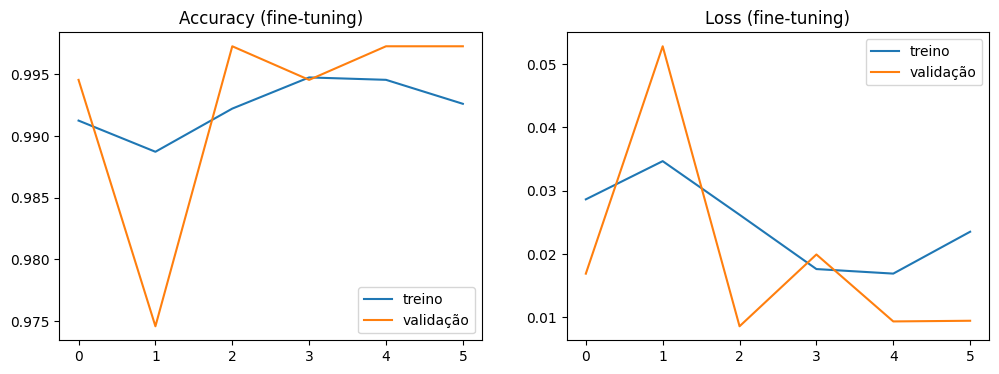

In [ ]:
# CURVAS DO FINE-TUNING

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_ft.history['accuracy'], label='treino')
plt.plot(history_ft.history['val_accuracy'], label='validação')
plt.title('Accuracy (fine-tuning)'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_ft.history['loss'], label='treino')
plt.plot(history_ft.history['val_loss'], label='validação')
plt.title('Loss (fine-tuning)'); plt.legend()

plt.show()

In [ ]:
# AVALIAÇÃO DO FINE-TUNING NO MESMO CONJUNTO DE TESTE

y_prob_ft = model.predict(test_data).flatten()
y_pred_ft = (y_prob_ft > 0.5).astype(int)

metricas_ft = {
    "accuracy": accuracy_score(y_true, y_pred_ft),
    "precision": precision_score(y_true, y_pred_ft, zero_division=0),
    "recall": recall_score(y_true, y_pred_ft, zero_division=0),
    "f1": f1_score(y_true, y_pred_ft, zero_division=0),
    "erros": int((y_pred_ft != y_true).sum()),
}

print(f"{'métrica':<12}{'baseline':>12}{'fine-tuning':>14}")
for k in metricas_base:
    b, f = metricas_base[k], metricas_ft[k]
    fmt = (lambda x: f"{x:.4f}") if isinstance(b, float) else (lambda x: f"{x}")
    print(f"{k:<12}{fmt(b):>12}{fmt(f):>14}")

print("\nNota: com 1.105 imagens de teste, uma diferença de 1 ou 2 erros é ruído, não prova de melhora.")

70/70 ━━━━━━━━━━━━━━━━━━━━ 9s 82ms/step
métrica         baseline   fine-tuning
accuracy          0.9955        0.9973
precision         1.0000        1.0000
recall            0.9921        0.9953
f1                0.9960        0.9976
erros                  5             3

Nota: com 1.105 imagens de teste, uma diferença de 1 ou 2 erros é ruído, não prova de melhora.


**Comentário Tarefa 9:** o fine-tuning não melhorou o resultado de forma que possa ser atribuída ao método. O baseline teve 5 erros no teste (recall da classe defeituosa de 0,992) e o fine-tuning teve 3 erros (recall de 0,995).

- **Diferença:** 2 erros em 1.105 imagens. Essa diferença é ruído estatístico: com esse volume, uma troca de 1 ou 2 imagens muda o resultado sem significar que o modelo ficou melhor.
- **Treinamento:** o EarlyStopping parou na época 6, e os pesos restaurados são os da época 3, que teve a menor `val_loss` (0,0086). As curvas mostram treino e validação próximos, sem sinal de sobreajuste.
- **Conclusão:** o fine-tuning manteve o desempenho do baseline com 30 camadas liberadas. Para afirmar uma melhora, seria preciso repetir o treino com várias sementes e comparar a média, ou testar no conjunto oficial do dataset.

## Tarefa 10 – Grad-CAM: onde o modelo olha

O Grad-CAM gera um mapa de calor sobre a imagem, mostrando quais regiões mais influenciaram a probabilidade de `defectuosa`. A grade da última camada convolucional da MobileNetV2 tem 7×7 regiões, então o mapa é grosseiro: indica a região aproximada, não o contorno do defeito.

Usamos o modelo já ajustado pelo fine-tuning. Para cada imagem: calculamos o gradiente da probabilidade de `defectuosa` em relação à saída da última camada convolucional, fazemos a média desses gradientes por canal e combinamos o resultado num mapa 7×7, que ampliamos e sobrepomos à peça.

In [ ]:
# GRAD-CAM

import tensorflow as tf

ultima_conv = mobilenet.get_layer("out_relu")   # última ativação da MobileNetV2 (saída 7×7×1280)

# Modelo que vai da entrada da base até a última conv (a base é aninhada, então montamos o caminho direto)
conv_model = tf.keras.Model(mobilenet.input, ultima_conv.output)

# Camadas da cabeça, reaproveitadas pelo nome
camada_rescale = model.get_layer("rescaling")
camada_gap = model.get_layer("global_average_pooling2d")
camada_dense = model.get_layer("dense")
camada_dropout = model.get_layer("dropout")
camada_saida = model.get_layer("dense_1")

def gradcam(imagem_array):
    """Recebe uma imagem já em [0,1] com shape (224,224,3) e devolve o mapa de calor 7x7 normalizado e a probabilidade."""
    x = tf.convert_to_tensor(imagem_array[np.newaxis, ...], dtype=tf.float32)
    with tf.GradientTape() as tape:
        x_in = camada_rescale(x)                       # mesma conversão [0,1] -> [-1,1] do modelo
        conv_out = conv_model(x_in, training=False)    # mapa 7x7x1280
        tape.watch(conv_out)
        h = camada_gap(conv_out)
        h = camada_dense(h)
        h = camada_dropout(h, training=False)
        prob = camada_saida(h)                         # probabilidade de 'defectuosa'
        alvo = prob[:, 0]
    grads = tape.gradient(alvo, conv_out)              # gradiente da saída em relação ao mapa
    pesos = tf.reduce_mean(grads, axis=(0, 1, 2))      # importância média de cada canal
    mapa = tf.reduce_sum(conv_out[0] * pesos, axis=-1) # combinação ponderada dos canais
    mapa = tf.nn.relu(mapa)                            # só o que contribui positivamente
    mapa = mapa / (tf.reduce_max(mapa) + 1e-8)         # normaliza entre 0 e 1
    return mapa.numpy(), float(prob[0, 0])

print("Função gradcam() pronta.")

Função gradcam() pronta.


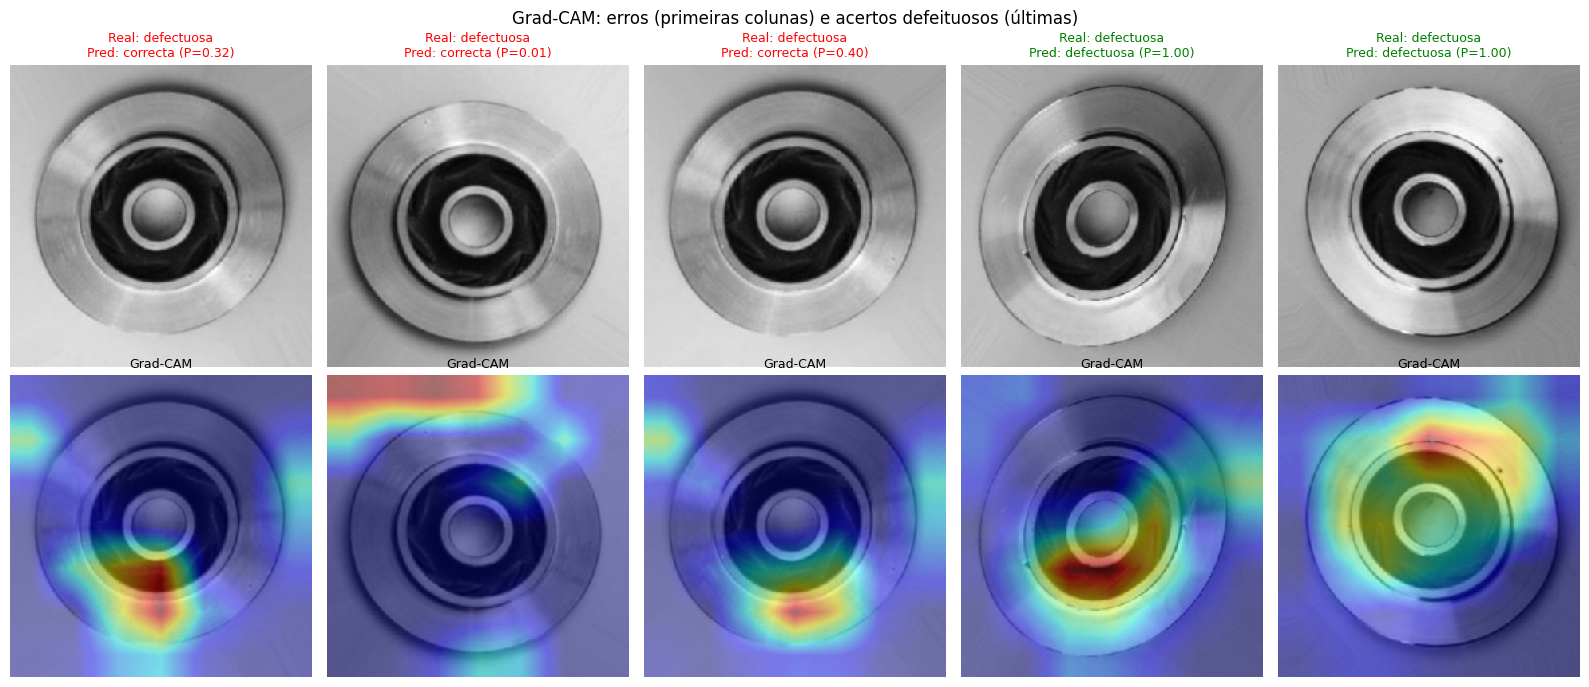

In [ ]:
# VISUALIZAR GRAD-CAM EM ACERTOS E ERROS DO TESTE

y_prob_teste = y_prob_ft
rutas_teste = np.array(test_data.filepaths)
nombres = ['correcta', 'defectuosa']

erros = np.where(y_pred_ft != y_true)[0]
acertos_def = np.where((y_pred_ft == y_true) & (y_true == 1))[0]
selecionados = list(erros[:4]) + list(acertos_def[:2])   # até 4 erros e 2 acertos defeituosos

fig, eixos = plt.subplots(2, len(selecionados), figsize=(3.2 * len(selecionados), 7))
for k, i in enumerate(selecionados):
    img = load_img(rutas_teste[i], target_size=IMG_SIZE)
    arr = img_to_array(img) / 255.0
    mapa, p = gradcam(arr)
    mapa_grande = tf.image.resize(mapa[..., np.newaxis], IMG_SIZE, method="bilinear").numpy()[..., 0]

    eixos[0, k].imshow(img)
    eixos[0, k].set_title(f"Real: {nombres[y_true[i]]}\nPred: {nombres[y_pred_ft[i]]} (P={p:.2f})",
                          fontsize=9, color="red" if y_pred_ft[i] != y_true[i] else "green")
    eixos[0, k].axis("off")

    eixos[1, k].imshow(img)
    eixos[1, k].imshow(mapa_grande, cmap="jet", alpha=0.45)
    eixos[1, k].set_title("Grad-CAM", fontsize=9)
    eixos[1, k].axis("off")

plt.suptitle("Grad-CAM: erros (primeiras colunas) e acertos defeituosos (últimas)", fontsize=12)
plt.tight_layout()
plt.show()

**Comentário Tarefa 10:** o Grad-CAM mostra que o modelo concentra a atenção sobretudo na região central da peça (o miolo e o anel interno), e não apenas nas bordas, o que seria um sinal de atalho.

- **Nos acertos defeituosos:** o calor fica na área central da peça, onde o defeito costuma aparecer. Pela resolução das figuras não é possível confirmar que o calor cai exatamente sobre a marca do defeito.
- **Nos erros:** o calor é mais fraco e mais espalhado. Em duas imagens ele aparece também na borda superior e lateral, fora da peça. Isso sugere que o modelo não se apoia no defeito nesses casos, e que o erro vem de uma região do fundo ou da borda, não da marca em si.
- **Limite do método:** o mapa tem resolução 7×7, então indica a região aproximada e não o contorno do defeito. Para validar a interpretação, seria preciso ampliar as imagens com a marca do defeito anotada à mão.

## Conclusão

**O que foi feito:** transfer learning com MobileNetV2 (pesos do ImageNet) e uma cabeça de classificação binária, treinada sobre o dataset completo de fundição (7.348 imagens: 5.142 para treino, 1.101 para validação e 1.105 para teste). Depois, fine-tuning das últimas 30 camadas da base e análise visual com Grad-CAM.

**Resultados no teste:**

| Modelo | Accuracy | Precisão (defeituosa) | Recall (defeituosa) | F1 | Erros |
|---|---|---|---|---|---|
| Baseline (base congelada) | 0,995 | 1,000 | 0,992 | 0,996 | 5 |
| Fine-tuning | 0,997 | 1,000 | 0,995 | 0,998 | 3 |

**Leitura dos resultados:**
- Os dois modelos são muito próximos. A diferença de 2 erros não permite dizer que o fine-tuning é melhor, então a conclusão honesta é que ele manteve o desempenho sem piorar.
- Em todos os casos a precisão ficou em 1,000: o modelo não marcou peça boa como defeituosa. O risco está nos falsos negativos, que foram 5 no baseline e 3 no fine-tuning.
- O Grad-CAM indica que o modelo olha principalmente para a região central da peça. Nos erros, a atenção fica mais espalhada e chega à borda, o que sugere que nem sempre ele se apoia no defeito.

**Limitações:**
- **Divisão aleatória:** o dataset tem variações da mesma peça, então treino e teste podem ter imagens muito parecidas. Isso pode tornar os resultados otimistas.
- **Um teste pequeno:** com 1.105 imagens e poucos erros, cada imagem pesa muito na métrica.
- **Uma única semente:** não foi medida a variação entre treinos diferentes.
- **Sem localização:** o modelo classifica a peça, mas não aponta onde está o defeito.

**Serve para o VisionQC?** Como prova de conceito, sim: o modelo detecta 628 das 633 peças defeituosas com nenhum falso positivo. Para uso real, é preciso reduzir os falsos negativos e validar em peças novas, que o modelo nunca viu.